# 03 - Modèle : architecture, entraînement, évaluation

Ce notebook reprend les étapes 2 à 6 du sujet (code dans `src/cnn.py`, `src/optimize.py`, `src/main.py`) :

2. l'architecture du CNN
3. l'entraînement avec les callbacks et les courbes
4. l'évaluation sur le jeu de test
5. la recherche des hyperparamètres
6. la sauvegarde et le rechargement du modèle

Le notebook **ne réentraîne rien** : il relit le modèle et les résultats produits par

```
python src/main.py optimize --trials 15
python src/main.py train --config best
```

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from PIL import Image

sns.set_theme(style="whitegrid")

from cnn import count_parameters, evaluate, load_model, predict
from load_data import (CLASS_NAMES, get_dataloaders, load_brain_tumor_data, prepare_dataset,
                        preprocess_for_inference)
from utils import get_device

device = get_device()
data = prepare_dataset()
model, ckpt = load_model(device=device)  # models/best_model.pt
config = ckpt["config"]
print(device, "|", config["model"], "|", config["training"])

cuda | {'filters': 48, 'dense': 128, 'dropout': 0.1} | {'batch_size': 16, 'epochs': 60, 'learning_rate': 0.000471705203762518, 'weight_decay': 0.0001, 'patience': 10, 'augment': True, 'num_workers': 0}


## 1. L'architecture (étape 2)

Le sujet demande au moins 4 couches de convolution. On a fait un CNN classique, que l'on peut expliquer ligne par ligne :

- **4 blocs** identiques : `Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2`
- le nombre de filtres **double** à chaque bloc pendant que l'image est **divisée par 2** : on perd en résolution, on gagne en nombre de motifs détectés
- une **moyenne globale** de chaque carte (`AdaptiveAvgPool`) : 1 nombre par filtre, donc très peu de paramètres dans la partie dense
- `Dense 128 → ReLU → Dropout → Dense 4` : 1 score par classe

In [2]:
print(model)
print(f"\nparamètres : {count_parameters(model):,}")

BrainTumorCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(48, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(96, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(192, 384, kernel_size=

In [3]:
# on suit la forme d'une image dans le réseau
x = torch.zeros(1, 1, 224, 224, device=device)
rows = [("entrée", tuple(x.shape[1:]))]
with torch.no_grad():
    for i, block in enumerate(model.features, 1):
        x = block(x)
        rows.append((f"bloc {i}", tuple(x.shape[1:])))
    x = model.pool(x)
    rows.append(("moyenne globale", tuple(x.shape[1:])))
    rows.append(("sortie", tuple(model.classifier(x).shape[1:])))
pd.DataFrame(rows, columns=["étape", "forme (canaux, hauteur, largeur)"])

,étape,"forme (canaux, hauteur, largeur)"
0,entrée,"(1, 224, 224)"
1,bloc 1,"(48, 112, 112)"
2,bloc 2,"(96, 56, 56)"
3,bloc 3,"(192, 28, 28)"
4,bloc 4,"(384, 14, 14)"
5,moyenne globale,"(384, 1, 1)"
6,sortie,"(4,)"


Pourquoi ces choix :

| Élément | À quoi il sert |
|---|---|
| Conv 3×3, `padding=1` | détecte des motifs locaux sans changer la taille de l'image |
| BatchNorm | remet les activations à la même échelle : entraînement plus stable et plus rapide |
| ReLU | la non-linéarité, sinon 4 convolutions reviendraient à une seule |
| MaxPool 2×2 | divise la taille par 2 et garde l'activation la plus forte |
| Moyenne globale | remplace un gros `Flatten` (14×14×filtres valeurs) par 1 valeur par filtre |
| Dropout | éteint des neurones au hasard pendant l'entraînement, contre le surapprentissage |

Le modèle reste petit (moins d'un million de paramètres) : il s'entraîne en une vingtaine de minutes sur un GPU de portable.

## 2. L'entraînement (étape 3)

- **Loss** : entropie croisée. **Optimiseur** : Adam, avec un léger `weight_decay`.
- **Augmentation** sur le train seulement : miroir horizontal, petite rotation / translation / zoom, légère variation de contraste.
- **3 callbacks** :
  1. `ReduceLROnPlateau` : le learning rate est divisé par 2 si la `val_loss` stagne 3 epochs
  2. *checkpoint* : on garde les poids de l'epoch qui a la meilleure `val_loss`
  3. *early stopping* : on arrête après 10 epochs sans amélioration

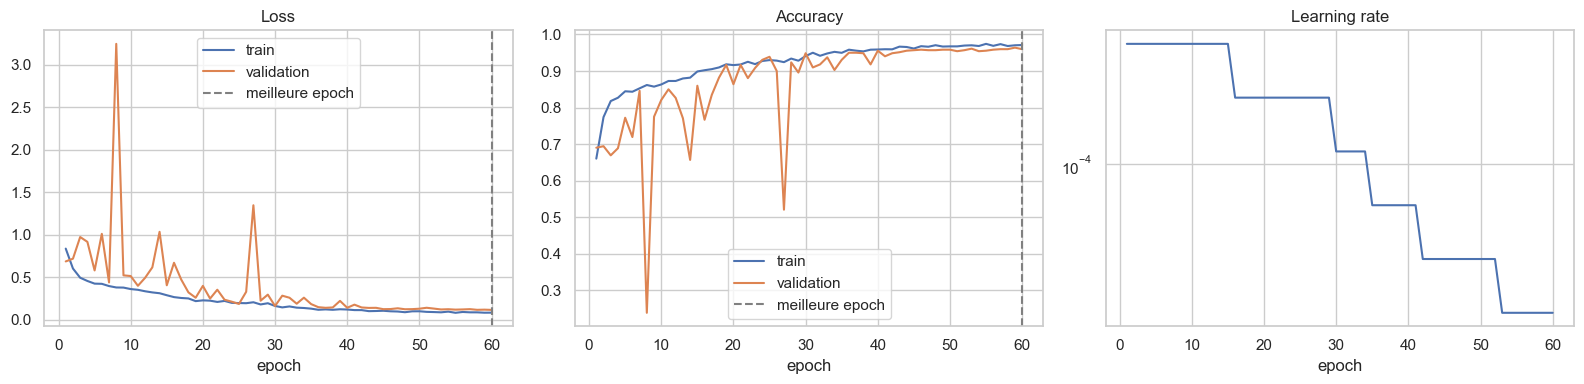

60 epochs, meilleure epoch : 60
train      : loss 0.083  accuracy 0.971
validation : loss 0.116  accuracy 0.960


In [4]:
history = json.loads((ROOT / "reports" / "history.json").read_text(encoding="utf-8"))
epochs = range(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, key in zip(axes, ["loss", "accuracy"]):
    ax.plot(epochs, history[key], label="train")
    ax.plot(epochs, history[f"val_{key}"], label="validation")
    ax.axvline(history["best_epoch"], color="grey", ls="--", label="meilleure epoch")
    ax.set(title=key.capitalize(), xlabel="epoch")
    ax.legend()
axes[2].plot(epochs, history["lr"])
axes[2].set(title="Learning rate", xlabel="epoch", yscale="log")
plt.tight_layout(); plt.show()

b = history["best_epoch"] - 1
print(f"{len(epochs)} epochs, meilleure epoch : {history['best_epoch']}")
print(f"train      : loss {history['loss'][b]:.3f}  accuracy {history['accuracy'][b]:.3f}")
print(f"validation : loss {history['val_loss'][b]:.3f}  accuracy {history['val_accuracy'][b]:.3f}")

**Lecture des courbes**

- Les courbes de train et de validation descendent ensemble et restent proches : **pas de surapprentissage** marqué (l'écart d'accuracy à la fin est d'environ 1 point).
- La validation est en dents de scie au début : le learning rate est encore grand. Chaque palier de la courbe du learning rate (divisé par 2) calme les oscillations.
- La meilleure epoch est la dernière (60) : la `val_loss` baissait encore très lentement. L'early stopping ne s'est donc pas déclenché ; quelques epochs de plus n'auraient apporté qu'un gain minime.

## 3. L'évaluation sur le test (étape 4)

Le jeu de test (1 600 images, 400 par classe) n'a servi **à aucun choix** : ni pour les callbacks, ni pour Optuna. On le regarde seulement ici.

In [5]:
_, val_loader, test_loader = get_dataloaders(data, batch_size=64)
val = evaluate(model, val_loader, device)
test = evaluate(model, test_loader, device)
print(f"validation : accuracy {val['accuracy']:.4f}  loss {val['loss']:.4f}")
print(f"test       : accuracy {test['accuracy']:.4f}  loss {test['loss']:.4f}")

report = pd.DataFrame(test["classification_report"]).T.loc[CLASS_NAMES + ["macro avg"]]
report.rename(columns={"precision": "précision", "recall": "rappel", "support": "images"}).round(3)

validation : accuracy 0.9597  loss 0.1156
test       : accuracy 0.8975  loss 0.5165


,précision,rappel,f1-score,images
glioma,0.987,0.750,0.852,400.0
meningioma,0.850,0.868,0.859,400.0
notumor,0.827,0.992,0.902,400.0
pituitary,0.961,0.980,0.970,400.0
macro avg,0.906,0.898,0.896,1600.0


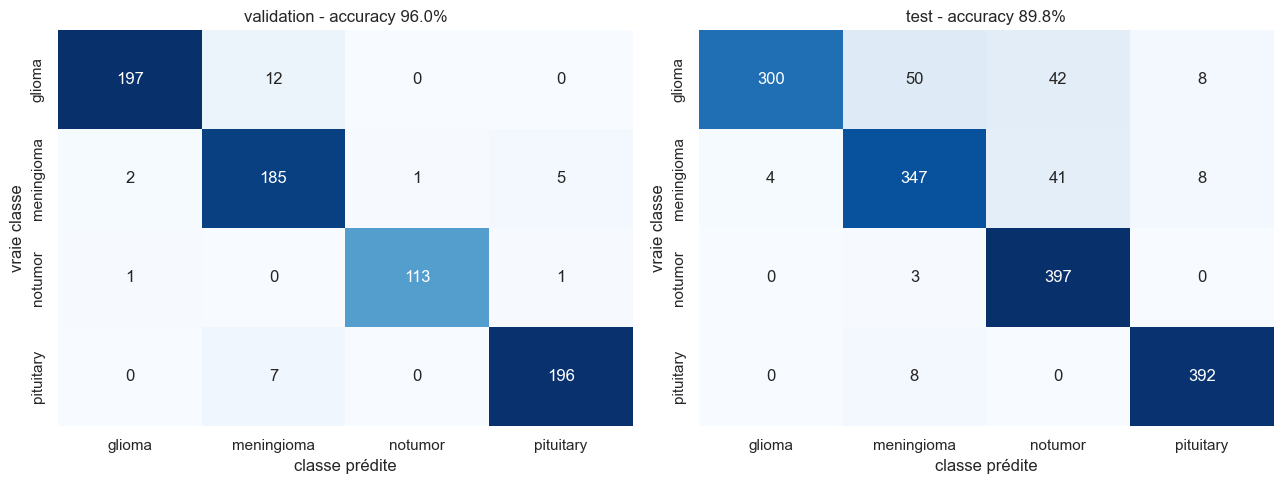

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, m) in zip(axes, [("validation", val), ("test", test)]):
    sns.heatmap(m["confusion_matrix"], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set(title=f"{name} - accuracy {m['accuracy']:.1%}", xlabel="classe prédite",
           ylabel="vraie classe")
plt.tight_layout(); plt.show()

**Ce qu'on lit**

- **pituitary** et **notumor** sont presque toujours retrouvées (rappel 98 % et 99 %).
- Les erreurs sont concentrées sur **glioma** (rappel 75 %) et **meningioma** (87 %) : une partie est prédite *meningioma* (confusion entre deux tumeurs, attendue) et une partie *notumor*.
- La précision de notumor (83 %) est donc la plus basse : quand le modèle dit « pas de tumeur », il se trompe environ 1 fois sur 6. Dans un contexte médical c'est **l'erreur la plus grave** (une tumeur manquée), il faut le dire clairement.
- Sur la validation, ces erreurs n'existent presque pas (96 %). L'écart validation / test ne vient donc pas d'un surapprentissage classique : la section suivante montre d'où il vient.

## 4. D'où viennent les erreurs : deux sources d'images

Dans l'EDA, on a vu que presque toutes les tumeurs du dossier `Training` sont des images **512×512**. Le dossier `Testing` contient en plus des tumeurs d'une **autre taille**, donc d'une autre origine (autre hôpital, autre machine). On sépare l'accuracy du test selon la taille du fichier d'origine.

In [7]:
raw = load_brain_tumor_data()
sizes = [Image.open(raw / p).size for p in data.stats["test_paths"]]
y, proba = predict(model, test_loader, device)

df = pd.DataFrame({"classe": [CLASS_NAMES[k] for k in y], "correct": proba.argmax(1) == y,
                   "source": ["512×512" if s == (512, 512) else "autre taille" for s in sizes]})
table = df.pivot_table(index="classe", columns="source", values="correct", aggfunc=["mean", "size"])
table.columns = [f"{'accuracy' if a == 'mean' else 'images'} {b}" for a, b in table.columns]
display(table.round(3))
print("accuracy par source :", df.groupby("source")["correct"].mean().round(3).to_dict())

# part des images 512×512 dans Training, par classe
part = {}
for c in CLASS_NAMES:
    files = sorted((raw / "Training" / c).iterdir())
    part[c] = round(float(np.mean([Image.open(f).size == (512, 512) for f in files])), 2)
print("part de 512×512 dans Training :", part)

C:\Users\araba\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,accuracy 512×512,accuracy autre taille,images 512×512,images autre taille
classe,,,,
glioma,0.904,0.092,324,76
meningioma,0.982,0.590,283,117
notumor,1.000,0.992,3,397
pituitary,0.980,1.000,392,8


accuracy par source : {'512×512': 0.956, 'autre taille': 0.799}


part de 512×512 dans Training : {'glioma': 1.0, 'meningioma': 0.91, 'notumor': 0.01, 'pituitary': 0.95}


**Conclusion**

- Sur les tumeurs en 512×512 (la source vue à l'entraînement), le modèle est bon, au niveau de la validation.
- Sur les gliomes et méningiomes d'une autre taille, il se trompe beaucoup : il n'en a presque jamais vu pendant l'entraînement (aucun gliome d'une autre taille dans `Training`).
- Pour notumor c'est l'inverse : presque aucune image n'est en 512×512, et le modèle les reconnaît très bien.

Le modèle a donc appris en partie le **style de la source** en plus de la tumeur. C'est une **limite du dataset** (il assemble plusieurs sources, et la classe dépend de la source), pas un réglage que l'on pourrait corriger avec plus d'epochs. C'est aussi pour ça que l'on affiche les métriques par classe et que le Grad-CAM est utile : il permet de vérifier où le modèle regarde.

## 5. Les choix testés avant le modèle final

Tous ces choix ont été faits **sur la validation**. Le test est donné à titre d'information.

| Version | Validation | Test |
|---|---|---|
| Normalisation globale (moyenne / écart-type du train), 40 epochs | 93,8 % | 84,4 % |
| Normalisation **par image**, 40 epochs | 95,3 % | 88,1 % |
| Par image + augmentation forte (contraste, flou, JPEG) | 95,0 % | 87,8 % |
| Par image, 60 epochs, loss pondérée par classe | 96,0 % | 88,9 % |
| Par image, 60 epochs, sans pondération | 96,0 % | 89,3 % |
| **Modèle final** (hyperparamètres Optuna, 60 epochs) | **96,0 %** | **89,8 %** |

- **Normalisation par image** : c'est le changement qui compte le plus. Avec la normalisation globale, le modèle utilisait la luminosité (les notumor sont plus claires) : sur le test, 37 % des gliomes enregistrés en RGB étaient prédits notumor, contre 0 % des gliomes enregistrés en niveaux de gris.
- **Augmentation forte** et **pondération de la loss** : pas de gain sur la validation, donc non gardées. On reste sur la version la plus simple.

**Et si on n'avait pas retiré les copies du test ?** Avec le protocole naïf (les 407 images de `Training` qui sont des copies d'images de `Testing` laissées en place), le même réseau affiche 91,4 % sur le test au lieu de 89,3 %. Ces 2 points sont de la **fuite de données**, pas de la qualité : on a gardé le chiffre honnête.

## 6. Recherche des hyperparamètres (étape 5)

On utilise **Optuna** sur les 4 hyperparamètres demandés :

| Hyperparamètre | Valeurs explorées |
|---|---|
| learning rate | de 0,0001 à 0,003 (échelle log) |
| batch size | 16, 32, 64 |
| filtres du 1er bloc | 16, 32, 48 |
| dropout | de 0,1 à 0,5 |

- 15 essais de 15 epochs maximum : des entraînements courts, qui servent juste à **comparer** des réglages.
- Critère : la meilleure `val_loss` (jamais le test).
- Le *pruner* arrête les essais qui partent moins bien que la médiane des précédents, pour ne pas perdre de temps.

In [8]:
trials = pd.read_csv(ROOT / "reports" / "optuna_trials.csv")
cols = {"number": "essai", "params_learning_rate": "learning rate", "params_batch_size": "batch",
        "params_filters": "filtres", "params_dropout": "dropout", "value": "val_loss",
        "user_attrs_val_accuracy": "val_accuracy", "state": "état"}
t = trials[list(cols)].rename(columns=cols)
display(t.sort_values("val_loss").round(4).reset_index(drop=True))
print(t["état"].value_counts().to_dict())

,essai,learning rate,batch,filtres,dropout,val_loss,val_accuracy,état
0,3,0.0005,16,48,0.1,0.2773,0.9125,COMPLETE
1,0,0.0004,16,16,0.5,0.2896,0.9014,COMPLETE
2,2,0.0003,16,16,0.2,0.3814,0.8514,COMPLETE
3,11,0.0003,16,16,0.5,0.3889,0.8375,COMPLETE
4,1,0.0008,64,16,0.1,0.4242,0.8486,COMPLETE
5,9,0.0001,16,16,0.1,0.4269,NaN,PRUNED
6,5,0.0002,64,32,0.3,0.5162,NaN,PRUNED
7,14,0.0003,32,48,0.2,0.6053,NaN,PRUNED
8,13,0.0001,16,16,0.3,0.6602,NaN,PRUNED
9,4,0.0001,32,48,0.3,0.7570,NaN,PRUNED


{'PRUNED': 10, 'COMPLETE': 5}


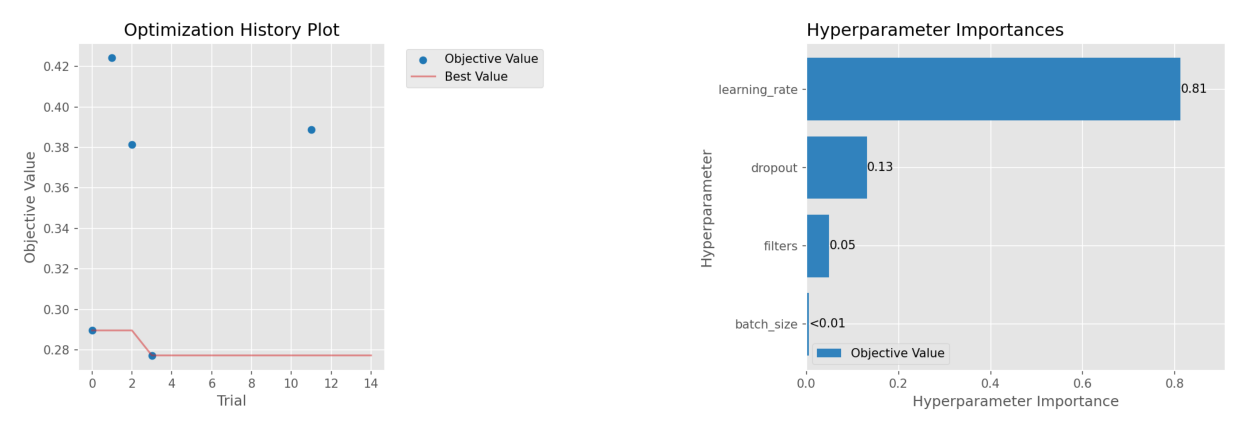

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name in zip(axes, ["optuna_history", "optuna_importance"]):
    ax.imshow(Image.open(FIG / f"{name}.png")); ax.axis("off")
plt.tight_layout(); plt.show()

**Résultat**

- Meilleur essai : **learning rate ≈ 0,0005, batch 16, 48 filtres, dropout 0,1** (`configs/best.yaml`).
- 5 essais sont allés au bout, 10 ont été coupés par le pruner. Pour un essai coupé, la `val_loss` affichée est celle du moment où il a été arrêté.
- Tendance : les **petits batchs** (16) marchent mieux que 64 (plus de mises à jour des poids par epoch), et plus de filtres aide.

**À dire honnêtement** : 15 essais courts, c'est une petite recherche. Une fois réentraînée sur 60 epochs, la configuration Optuna fait à peine mieux que notre réglage de départ (val_loss 0,116 contre 0,119, même accuracy de 96,0 %). La conclusion est que le modèle est **peu sensible** à ces hyperparamètres : ce sont les choix sur les données (nettoyage, normalisation) qui ont fait la différence.

## 7. Sauvegarde et rechargement (étape 6)

`models/best_model.pt` contient les poids **et** la configuration : on peut reconstruire le modèle sans le code d'entraînement. C'est ce fichier que l'application Streamlit charge.

On vérifie que le modèle rechargé, avec le prétraitement de l'application (`preprocess_for_inference`), donne les mêmes prédictions que pendant l'évaluation.

In [10]:
print("contenu du fichier :", list(ckpt))
print("taille :", round((ROOT / "models" / "best_model.pt").stat().st_size / 1e6, 1), "Mo")

reloaded, _ = load_model(device="cpu")
idx = np.random.default_rng(0).choice(len(y), 100, replace=False)  # 100 images du test au hasard
same = 0
for i in idx:
    img = Image.open(raw / data.stats["test_paths"][i])
    with torch.no_grad():
        p = torch.softmax(reloaded(preprocess_for_inference(img, ckpt["stats"])), 1)[0].numpy()
    same += int(p.argmax() == proba[i].argmax() and np.allclose(p, proba[i], atol=1e-3))
print(f"prédictions identiques (appli vs évaluation) : {same}/100")

contenu du fichier : ['state_dict', 'config', 'class_names', 'stats', 'metrics']
taille : 3.7 Mo


prédictions identiques (appli vs évaluation) : 100/100


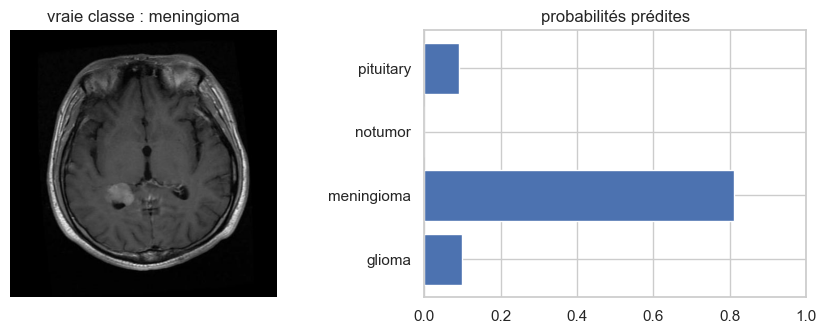

In [11]:
# un exemple, comme dans l'application
i = idx[0]
img = Image.open(raw / data.stats["test_paths"][i])
with torch.no_grad():
    p = torch.softmax(reloaded(preprocess_for_inference(img, ckpt["stats"])), 1)[0].numpy()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].imshow(img, cmap="gray"); axes[0].axis("off")
axes[0].set_title(f"vraie classe : {CLASS_NAMES[y[i]]}")
axes[1].barh(CLASS_NAMES, p); axes[1].set(xlim=(0, 1), title="probabilités prédites")
plt.tight_layout(); plt.show()

## Bilan

- **Modèle** : CNN de 4 blocs de convolution, moins d'un million de paramètres, entraîné en une vingtaine de minutes.
- **Validation : 96,0 %. Test : 89,8 %**, sans aucune image du test (ni copie) dans l'entraînement.
- pituitary et notumor : rappel de 98-99 %. Le point faible est le rappel des **gliomes** (75 %).
- L'écart validation / test vient d'une **deuxième source d'images** présente dans le test et absente des tumeurs d'entraînement. Sur la source principale, le modèle est au niveau de la validation.
- Ce qui a compté : le **nettoyage des données** (doublons, copies du test) et la **normalisation par image**. Les hyperparamètres comptent peu.

**Limites et pistes**

- Le dataset mélange des sources, et la classe dépend en partie de la source : un score sur ce test ne dit pas ce que le modèle ferait dans un vrai hôpital.
- Piste : ajouter des tumeurs d'autres sources à l'entraînement, ou du transfert d'apprentissage (modèle pré-entraîné).
- Le Grad-CAM (application) permet de vérifier, image par image, que le modèle regarde bien la tumeur.